# Fraud Detection System for Financial Transactions (one notebook)

**How to run (important):**
1. Runtime → **Run all**. It takes roughly 15–25 minutes, mostly autoencoder training. A CPU runtime is fine.
2. Near the end (section 12) Colab asks to connect Google Drive. Click through and **allow** it; this saves your models.
3. The last cell opens a Gradio demo web app. Before using it, check that sections 9 and 10 print `ALL CHECKS PASSED`.
4. If anything breaks: **Runtime → Restart session**, then **Run all**. Always run from the top and never edit cells in the middle.

**What it builds:** Isolation Forest and a PyTorch autoencoder (unsupervised anomaly detectors), compared honestly against a supervised XGBoost baseline on the ULB credit-card dataset (0.17% fraud). The final system uses **XGBoost as the main decision** and the **autoencoder as a second opinion**, served by one shared scoring file (`fraud_core.py`) through a FastAPI app, a SageMaker-ready package and the Gradio demo.

## 1. Setup and data

In [2]:
!pip install -q kagglehub shap

In [3]:
import os, json, random, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Files:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "creditcard.csv"))
print(df.shape)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Files: ['creditcard.csv']
(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. SQL: store and query the transactions (SQLite)
We load the raw data into a local SQLite database and run example investigation queries.

In [4]:
conn = sqlite3.connect("fraud.db")
df.to_sql("transactions", conn, if_exists="replace", index=False)
conn.execute("CREATE INDEX IF NOT EXISTS idx_class ON transactions(Class)")
conn.commit()

q1 = """
SELECT Class,
       COUNT(*) AS n_transactions,
       ROUND(AVG(Amount), 2) AS avg_amount
FROM transactions
GROUP BY Class
"""
print(pd.read_sql(q1, conn))

q2 = """
SELECT (CAST(Time / 3600 AS INTEGER) % 24) AS hour_of_day,
       COUNT(*) AS total,
       SUM(Class) AS frauds
FROM transactions
GROUP BY hour_of_day
ORDER BY hour_of_day
"""
print(pd.read_sql(q2, conn))

q3 = """
SELECT Time, Amount, Class
FROM transactions
WHERE Class = 1
ORDER BY Amount DESC
LIMIT 5
"""
print(pd.read_sql(q3, conn))

   Class  n_transactions  avg_amount
0      0          284315       88.29
1      1             492      122.21
    hour_of_day  total  frauds
0             0   7695       6
1             1   4220      10
2             2   3328      57
3             3   3492      17
4             4   2209      23
5             5   2990      11
6             6   4101       9
7             7   7243      23
8             8  10276       9
9             9  15838      16
10           10  16598       8
11           11  16856      53
12           12  15420      17
13           13  15365      17
14           14  16570      23
15           15  16461      26
16           16  16453      22
17           17  16166      29
18           18  17039      33
19           19  15649      19
20           20  16756      18
21           21  17703      16
22           22  15441       9
23           23  10938      21
       Time   Amount  Class
0  122608.0  2125.87      1
1    9064.0  1809.68      1
2  154278.0  1504.93      1
3 

## 3. Exploratory data analysis
Look for missing values, duplicates and the class imbalance. **Expected:** 0 missing values, 1081 duplicate rows, 492 frauds (about 0.173%).

Missing values: 0
Duplicate rows: 1081
Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.173%


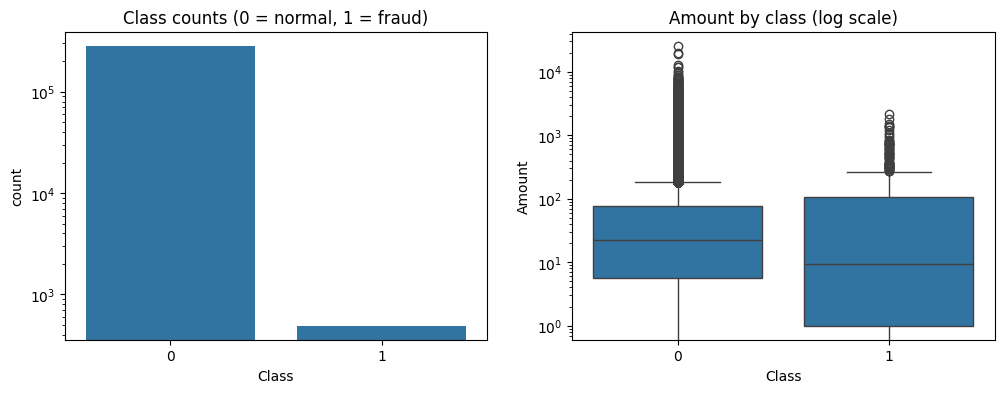

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print(df["Class"].value_counts())
print(f"Fraud percentage: {df['Class'].mean() * 100:.3f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="Class", data=df, ax=ax[0])
ax[0].set_title("Class counts (0 = normal, 1 = fraud)")
ax[0].set_yscale("log")

sns.boxplot(x="Class", y="Amount", data=df, ax=ax[1])
ax[1].set_yscale("log")
ax[1].set_title("Amount by class (log scale)")
plt.show()

corr = df.corr()["Class"].drop("Class").sort_values()
print(corr.head(5))
print(corr.tail(5))

## 4. Preprocessing
- Remove duplicate rows **before** splitting.
- Drop `Time`, log-transform `Amount`, standardise all features.
- Stratified 60 / 20 / 20 split (train / validation / test).
- The scaler is fitted on **training genuine rows only**, so nothing leaks from validation or test.

**Expected:** about 283,726 rows, 473 frauds, `Features used: 29`, `NaNs anywhere: False`.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicate rows -> {len(df)} rows left")
print("Frauds remaining:", int(df["Class"].sum()))

# Time is dropped on purpose (seconds since the first transaction; it does not generalise).
# Amount is log-transformed because it is extremely skewed. The column keeps the name 'Amount'.
RAW_FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount"]

def make_features(raw):
    out = raw[RAW_FEATURES].copy()
    out["Amount"] = np.log1p(out["Amount"])
    return out

X = make_features(df)
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Fit the scaler on TRAIN GENUINE rows only
scaler = StandardScaler().fit(X_train[y_train == 0])

def scale(X_):
    return pd.DataFrame(scaler.transform(X_), columns=X_.columns, index=X_.index)

X_train, X_val, X_test = scale(X_train), scale(X_val), scale(X_test)
X_train_normal = X_train[y_train == 0]

print("Features used:", X_train.shape[1])
print("Train (all):", X_train.shape, "| frauds:", int(y_train.sum()))
print("Train (normal only):", X_train_normal.shape)
print("Val:", X_val.shape, "| frauds:", int(y_val.sum()))
print("Test:", X_test.shape, "| frauds:", int(y_test.sum()))
print("NaNs anywhere:", bool(X_train.isna().any().any() or X_val.isna().any().any() or X_test.isna().any().any()))

Removed 1081 duplicate rows -> 283726 rows left
Frauds remaining: 473
Features used: 29
Train (all): (170235, 29) | frauds: 284
Train (normal only): (169951, 29)
Val: (56745, 29) | frauds: 94
Test: (56746, 29) | frauds: 95
NaNs anywhere: False


## 5. Isolation Forest
Trained on genuine rows only. `max_samples` is chosen by **validation** PR-AUC, and the decision threshold is chosen on **validation** only. The test set is only used for the final report.

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve)

def best_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

def evaluate(name, y_true, scores, thr):
    pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    print(f"--- {name} ---")
    print(f"Precision: {precision_score(y_true, pred, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_true, pred):.3f}")
    print(f"F1:        {f1_score(y_true, pred):.3f}")
    print(f"PR-AUC:    {average_precision_score(y_true, scores):.3f}")
    print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}\n")

# max_features stays at 1.0 on purpose: SHAP's TreeExplainer does not handle
# per-tree feature subsets correctly for IsolationForest.
best_ap, iso = -1, None
for max_samples in [256, 1024, 4096]:
    cand = IsolationForest(n_estimators=200, max_samples=max_samples,
                           random_state=42, n_jobs=-1).fit(X_train_normal)
    ap = average_precision_score(y_val, -cand.score_samples(X_val))
    print(f"max_samples={max_samples:5d} -> validation PR-AUC {ap:.3f}")
    if ap > best_ap:
        best_ap, iso, best_ms = ap, cand, max_samples
print("Chosen max_samples:", best_ms)

# score_samples: higher = more normal, so we negate it: higher = more anomalous
iso_val  = -iso.score_samples(X_val)
iso_test = -iso.score_samples(X_test)

thr_iso = best_threshold(y_val, iso_val)
evaluate("Isolation Forest (validation, threshold tuned here)", y_val, iso_val, thr_iso)
evaluate("Isolation Forest (TEST)", y_test, iso_test, thr_iso)

max_samples=  256 -> validation PR-AUC 0.087
max_samples= 1024 -> validation PR-AUC 0.100
max_samples= 4096 -> validation PR-AUC 0.140
Chosen max_samples: 4096
--- Isolation Forest (validation, threshold tuned here) ---
Precision: 0.235
Recall:    0.340
F1:        0.278
PR-AUC:    0.140
TP=32  FP=104  FN=62  TN=56547

--- Isolation Forest (TEST) ---
Precision: 0.248
Recall:    0.379
F1:        0.300
PR-AUC:    0.233
TP=36  FP=109  FN=59  TN=56542



## 6. PyTorch autoencoder
Trained on **genuine transactions only**. It learns to reconstruct normal behaviour, so a transaction it reconstructs badly (high reconstruction error) is suspicious. Training takes a few minutes on CPU and prints one line per epoch.

Using: cpu
Epoch 01 | train 0.9239 | val 0.8763
Epoch 02 | train 0.7878 | val 0.7701
Epoch 03 | train 0.7124 | val 0.7114
Epoch 04 | train 0.6654 | val 0.6674
Epoch 05 | train 0.6382 | val 0.6432
Epoch 06 | train 0.6183 | val 0.6230
Epoch 07 | train 0.6047 | val 0.6076
Epoch 08 | train 0.5949 | val 0.5999
Epoch 09 | train 0.5868 | val 0.5932
Epoch 10 | train 0.5803 | val 0.5852
Epoch 11 | train 0.5747 | val 0.5792
Epoch 12 | train 0.5698 | val 0.5718
Epoch 13 | train 0.5663 | val 0.5711
Epoch 14 | train 0.5632 | val 0.5692
Epoch 15 | train 0.5606 | val 0.5647
Epoch 16 | train 0.5589 | val 0.5624
Epoch 17 | train 0.5568 | val 0.5606
Epoch 18 | train 0.5553 | val 0.5581
Epoch 19 | train 0.5533 | val 0.5560
Epoch 20 | train 0.5517 | val 0.5577
Epoch 21 | train 0.5506 | val 0.5550
Epoch 22 | train 0.5489 | val 0.5531
Epoch 23 | train 0.5475 | val 0.5521
Epoch 24 | train 0.5459 | val 0.5500
Epoch 25 | train 0.5440 | val 0.5482
Epoch 26 | train 0.5428 | val 0.5465
Epoch 27 | train 0.5408 | v

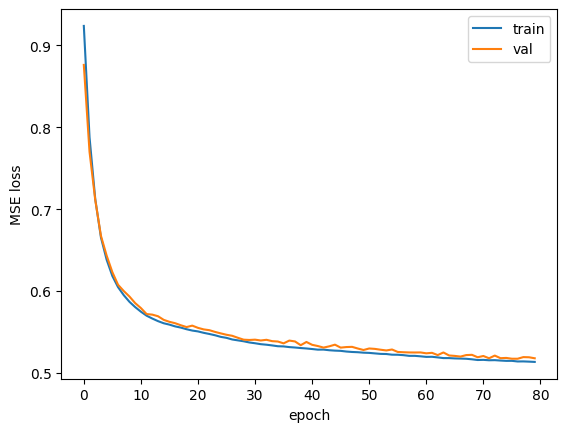

In [8]:
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

class AutoEncoder(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n, 16), nn.ReLU(),
                                 nn.Linear(16, 8),  nn.ReLU(),
                                 nn.Linear(8, 4))
        self.dec = nn.Sequential(nn.Linear(4, 8),   nn.ReLU(),
                                 nn.Linear(8, 16),  nn.ReLU(),
                                 nn.Linear(16, n))
    def forward(self, x):
        return self.dec(self.enc(x))

Xtr = torch.tensor(X_train_normal.values, dtype=torch.float32)                 # genuine rows only
Xva = torch.tensor(X_val[y_val == 0].values, dtype=torch.float32).to(device)   # genuine validation rows

ae = AutoEncoder(n=X_train.shape[1]).to(device)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
loader = DataLoader(TensorDataset(Xtr), batch_size=512, shuffle=True)

best, patience, wait, best_state = float("inf"), 8, 0, None
train_hist, val_hist = [], []

for epoch in range(80):
    ae.train()
    total = 0
    for (b,) in loader:
        b = b.to(device)
        opt.zero_grad()
        loss = loss_fn(ae(b), b)
        loss.backward()
        opt.step()
        total += loss.item() * len(b)
    tr = total / len(Xtr)

    ae.eval()
    with torch.no_grad():
        va = loss_fn(ae(Xva), Xva).item()
    train_hist.append(tr); val_hist.append(va)
    print(f"Epoch {epoch+1:02d} | train {tr:.4f} | val {va:.4f}")

    if va < best:                      # early stopping on validation loss
        best, wait = va, 0
        best_state = {k: v.cpu().clone() for k, v in ae.state_dict().items()}
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping"); break

ae.load_state_dict(best_state)

plt.plot(train_hist, label="train"); plt.plot(val_hist, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.legend(); plt.show()

--- Autoencoder (validation, threshold tuned here) ---
Precision: 0.509
Recall:    0.309
F1:        0.384
PR-AUC:    0.294
TP=29  FP=28  FN=65  TN=56623

--- Autoencoder (TEST) ---
Precision: 0.524
Recall:    0.347
F1:        0.418
PR-AUC:    0.421
TP=33  FP=30  FN=62  TN=56621



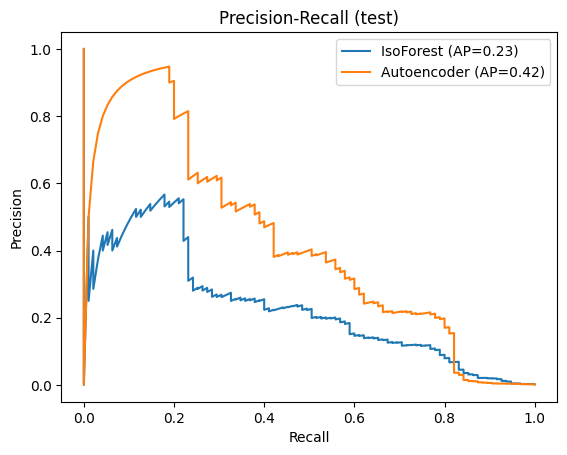

In [9]:
def recon_error(model, X):
    model.eval()
    with torch.no_grad():
        t = torch.tensor(X.values, dtype=torch.float32).to(device)
        return ((t - model(t)) ** 2).mean(dim=1).cpu().numpy()

ae_val  = recon_error(ae, X_val)
ae_test = recon_error(ae, X_test)

thr_ae = best_threshold(y_val, ae_val)       # threshold chosen on VALIDATION only
evaluate("Autoencoder (validation, threshold tuned here)", y_val, ae_val, thr_ae)
evaluate("Autoencoder (TEST)", y_test, ae_test, thr_ae)

for name, s in [("IsoForest", iso_test), ("Autoencoder", ae_test)]:
    p, r, _ = precision_recall_curve(y_test, s)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, s):.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend()
plt.title("Precision-Recall (test)"); plt.show()

## 7. Operating points and combining the two models
**Operating points:** thresholds are chosen on validation for a target precision, then the test result is *reported* (never used to choose).
Read this table carefully: high precision is usually only reachable at low recall, and the number of flagged transactions is small, so these figures are noisy.

In [10]:
p, r, t = precision_recall_curve(y_val, ae_val)

print("target | val precision/recall | TEST precision | TEST recall | flagged | TP")
for target in [0.7, 0.8, 0.9, 0.95]:
    ok = np.where(p[:-1] >= target)[0]
    if len(ok) == 0:
        print(f"{target:.2f}   | not reachable on validation"); continue
    thr = t[ok[0]]                      # lowest threshold that still meets the target
    pred = (ae_test >= thr).astype(int)
    print(f"{target:.2f}   | {p[ok[0]]:.2f} / {r[ok[0]]:.2f}"
          f"          | {precision_score(y_test, pred, zero_division=0):.2f}"
          f"           | {recall_score(y_test, pred):.2f}"
          f"        | {pred.sum():3d}     | {int((pred & y_test.values).sum())}")

target | val precision/recall | TEST precision | TEST recall | flagged | TP
0.70   | 0.71 / 0.13          | 0.90           | 0.19        |  20     | 18
0.80   | 0.83 / 0.11          | 0.92           | 0.13        |  13     | 12
0.90   | not reachable on validation
0.95   | not reachable on validation


In [11]:
# Combine the two scores. They have different scales, so each is log-transformed and standardised first.
# The weight w (0 = autoencoder only) is chosen on VALIDATION PR-AUC.
def logz(v, ref):
    lv, lr = np.log(v + 1e-9), np.log(ref + 1e-9)
    return (lv - lr.mean()) / lr.std()

iso_z_val,  iso_z_test = logz(iso_val, iso_val),  logz(iso_test, iso_val)
ae_z_val,   ae_z_test  = logz(ae_val,  ae_val),   logz(ae_test,  ae_val)

best_w, best_ap = 0, 0
for w in [0, 0.1, 0.2, 0.3, 0.5]:          # w = weight of Isolation Forest
    s = w * iso_z_val + (1 - w) * ae_z_val
    ap = average_precision_score(y_val, s)
    print(f"w={w}: validation PR-AUC {ap:.3f}")
    if ap > best_ap:
        best_w, best_ap = w, ap

print("Best w on validation:", best_w)
comb2_val  = best_w * iso_z_val  + (1 - best_w) * ae_z_val
comb2_test = best_w * iso_z_test + (1 - best_w) * ae_z_test
evaluate(f"Weighted combo w={best_w} (test)", y_test, comb2_test,
         best_threshold(y_val, comb2_val))

if best_w == 0:
    print("Validation chose w=0, so the FINAL system is the autoencoder alone: adding Isolation Forest did not help.")

w=0: validation PR-AUC 0.294
w=0.1: validation PR-AUC 0.290
w=0.2: validation PR-AUC 0.274
w=0.3: validation PR-AUC 0.261
w=0.5: validation PR-AUC 0.240
Best w on validation: 0
--- Weighted combo w=0 (test) ---
Precision: 0.524
Recall:    0.347
F1:        0.418
PR-AUC:    0.421
TP=33  FP=30  FN=62  TN=56621

Validation chose w=0, so the FINAL system is the autoencoder alone: adding Isolation Forest did not help.


In [12]:
# One tidy table of results for your README / resume. Thresholds come from validation.
def summary_row(model, split, y_true, scores, thr):
    pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"model": model, "split": split,
            "precision": round(precision_score(y_true, pred, zero_division=0), 3),
            "recall": round(recall_score(y_true, pred), 3),
            "f1": round(f1_score(y_true, pred), 3),
            "pr_auc": round(average_precision_score(y_true, scores), 3),
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

results = pd.DataFrame([
    summary_row("Isolation Forest", "validation", y_val,  iso_val,  thr_iso),
    summary_row("Isolation Forest", "test",       y_test, iso_test, thr_iso),
    summary_row("Autoencoder",      "validation", y_val,  ae_val,   thr_ae),
    summary_row("Autoencoder",      "test",       y_test, ae_test,  thr_ae),
])
results.to_csv("results.csv", index=False)
print(results.to_string(index=False))

           model      split  precision  recall    f1  pr_auc  TP  FP  FN    TN
Isolation Forest validation      0.235   0.340 0.278   0.140  32 104  62 56547
Isolation Forest       test      0.248   0.379 0.300   0.233  36 109  59 56542
     Autoencoder validation      0.509   0.309 0.384   0.294  29  28  65 56623
     Autoencoder       test      0.524   0.347 0.418   0.421  33  30  62 56621


## 7b. XGBoost supervised baseline
Isolation Forest and the autoencoder are **unsupervised**: they never see a fraud label while learning. XGBoost is **supervised**: it learns from the labelled frauds in the training set. It is a different kind of model, so it is a *benchmark* (how much do labels help?), not a replacement for the anomaly detectors.
Same rules as before: it is trained on the training set, early-stopped and thresholded on **validation**, and the test set is only used for the final report.

In [13]:
import sys, os
try:
    import xgboost as xgb
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost as xgb

# Fraud is ~0.17% of rows, so we up-weight the positive class.
# (This changes the probability scale, not the ranking; the threshold is chosen on validation anyway.)
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
spw = n_neg / n_pos
print(f"scale_pos_weight = {spw:.0f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric="aucpr", early_stopping_rounds=50,    # stops when validation PR-AUC stops improving
    tree_method="hist", random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Best iteration:", xgb_model.best_iteration)

xgb_val  = xgb_model.predict_proba(X_val)[:, 1]
xgb_test = xgb_model.predict_proba(X_test)[:, 1]

thr_xgb = best_threshold(y_val, xgb_val)         # threshold chosen on VALIDATION only
evaluate("XGBoost (validation, threshold tuned here)", y_val, xgb_val, thr_xgb)
evaluate("XGBoost (TEST)", y_test, xgb_test, thr_xgb)

scale_pos_weight = 598
Best iteration: 516
--- XGBoost (validation, threshold tuned here) ---
Precision: 0.945
Recall:    0.734
F1:        0.826
PR-AUC:    0.797
TP=69  FP=4  FN=25  TN=56647

--- XGBoost (TEST) ---
Precision: 0.974
Recall:    0.800
F1:        0.879
PR-AUC:    0.875
TP=76  FP=2  FN=19  TN=56649



target | val precision/recall | TEST precision | TEST recall | flagged | TP
0.80   | 0.80 / 0.79          | 0.92           | 0.84        |  87     | 80
0.90   | 0.91 / 0.74          | 0.97           | 0.81        |  79     | 77
0.95   | 0.96 / 0.72          | 0.97           | 0.78        |  76     | 74


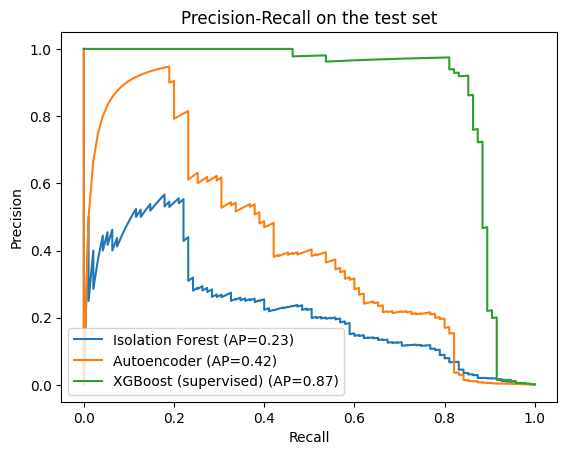

               model      split  precision  recall    f1  pr_auc  TP  FP  FN    TN
    Isolation Forest validation      0.235   0.340 0.278   0.140  32 104  62 56547
    Isolation Forest       test      0.248   0.379 0.300   0.233  36 109  59 56542
         Autoencoder validation      0.509   0.309 0.384   0.294  29  28  65 56623
         Autoencoder       test      0.524   0.347 0.418   0.421  33  30  62 56621
XGBoost (supervised) validation      0.945   0.734 0.826   0.797  69   4  25 56647
XGBoost (supervised)       test      0.974   0.800 0.879   0.875  76   2  19 56649


In [14]:
# Operating points for XGBoost: thresholds chosen on validation, test result only REPORTED
pv, rv, tv = precision_recall_curve(y_val, xgb_val)
print("target | val precision/recall | TEST precision | TEST recall | flagged | TP")
for target in [0.8, 0.9, 0.95]:
    ok = np.where(pv[:-1] >= target)[0]
    if len(ok) == 0:
        print(f"{target:.2f}   | not reachable on validation"); continue
    thr_t = tv[ok[0]]
    pred = (xgb_test >= thr_t).astype(int)
    print(f"{target:.2f}   | {pv[ok[0]]:.2f} / {rv[ok[0]]:.2f}"
          f"          | {precision_score(y_test, pred, zero_division=0):.2f}"
          f"           | {recall_score(y_test, pred):.2f}"
          f"        | {pred.sum():3d}     | {int((pred & y_test.values).sum())}")

# All three models on the test set
for name, s in [("Isolation Forest", iso_test), ("Autoencoder", ae_test), ("XGBoost (supervised)", xgb_test)]:
    pp, rr, _ = precision_recall_curve(y_test, s)
    plt.plot(rr, pp, label=f"{name} (AP={average_precision_score(y_test, s):.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend()
plt.title("Precision-Recall on the test set"); plt.show()

# Add XGBoost to the results table and save it
results = results[~results["model"].str.startswith("XGBoost")]
results = pd.concat([results, pd.DataFrame([
    summary_row("XGBoost (supervised)", "validation", y_val,  xgb_val,  thr_xgb),
    summary_row("XGBoost (supervised)", "test",       y_test, xgb_test, thr_xgb)])], ignore_index=True)
results.to_csv("results.csv", index=False)
print(results.to_string(index=False))

xgb_model.save_model("xgb_baseline.json")
import shutil
drive_dest = "/content/drive/MyDrive/fraud_detection_project"
if os.path.ismount("/content/drive") and os.path.isdir(drive_dest):   # only if Drive is really mounted
    for f in ["xgb_baseline.json", "results.csv"]:
        shutil.copy(f, drive_dest)
    print("Copied xgb_baseline.json and results.csv to Drive")

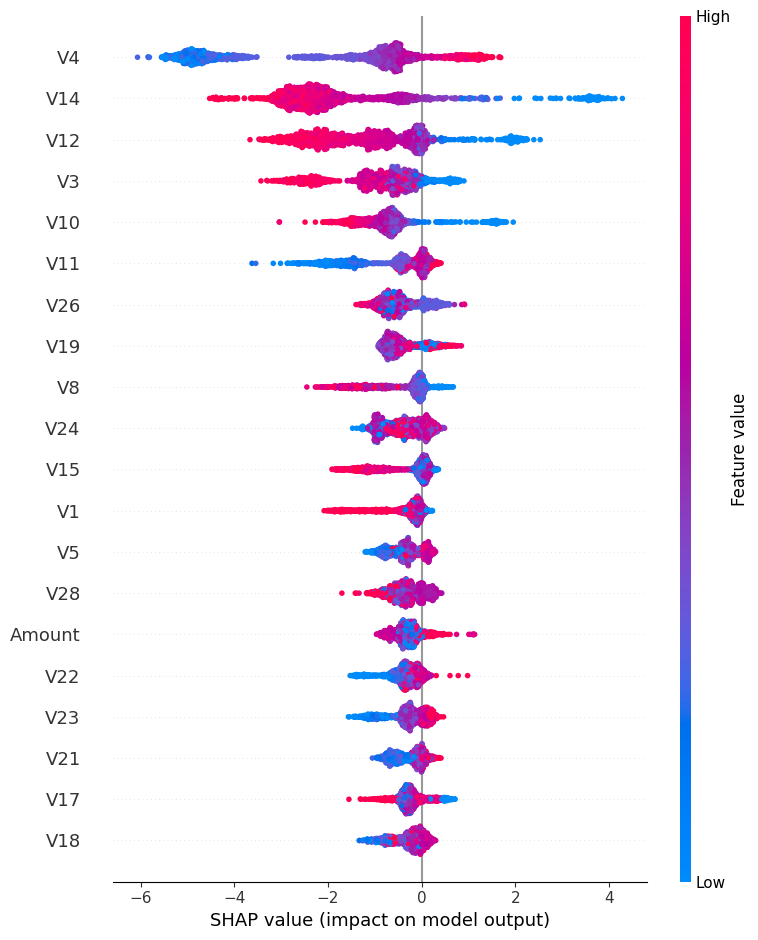

In [15]:
# Optional: SHAP for XGBoost. TreeExplainer is exact for tree models and explains the model's own score.
try:
    import shap
    xs = pd.concat([X_test[y_test == 0].sample(1500, random_state=42), X_test[y_test == 1]])
    xsv = shap.TreeExplainer(xgb_model).shap_values(xs)
    shap.summary_plot(xsv, xs)
except Exception as e:
    print("XGBoost SHAP skipped:", repr(e))

## 8. Export the trained models
Saves everything the serving code needs, all taken from **this run** so files and results always agree: XGBoost model and threshold, autoencoder weights, preprocessing numbers, and a small "golden" file (all test frauds plus 300 genuine transactions with the scores computed above). The checks in sections 9 and 10 must reproduce these scores exactly.

The `REVIEW rows` lines show how often the autoencoder flags something XGBoost does not, and how many of those are real frauds.

In [16]:
import json, os, shutil
import numpy as np, pandas as pd, torch

# 1) XGBoost model, its threshold, and the number of trees to use (early stopping trains extra trees past the best one)
xgb_model.save_model("xgb_baseline.json")
json.dump({"xgb_thr": float(thr_xgb), "best_iteration": int(xgb_model.best_iteration)},
          open("xgb_config.json", "w"))

# 2) Autoencoder weights + preprocessing config, taken from THIS session's trained objects
cols = list(X_train.columns)
cfg = {"cols": cols, "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
       "ae_thr": float(thr_ae), "log1p_cols": ["Amount"]}
json.dump(cfg, open("config.json", "w"))
torch.save({k: v.detach().cpu().clone() for k, v in ae.state_dict().items()}, "ae.pt")

# 3) "Golden" scores: ALL test frauds + 300 genuine test transactions (raw features) and the scores THIS
#    session computed for them. The serving notebook must reproduce these exactly.
rows = X_test[y_test == 1].index.append(X_test[y_test == 0].sample(300, random_state=0).index)
pos = X_test.index.get_indexer(rows)
golden = df.loc[rows].drop(columns="Class").copy()
golden["xgb_prob"] = xgb_test[pos]
golden["ae_score"] = ae_test[pos]
golden["xgb_flag"] = (xgb_test[pos] >= thr_xgb)      # the session's own decisions (exact, no CSV rounding)
golden["ae_flag"] = (ae_test[pos] >= thr_ae)
golden["y_true"] = y_test.loc[rows].values
golden.to_csv("golden_scores.csv", index=False)

# 4) How many extra 'REVIEW' flags does the autoencoder add on top of XGBoost? (informational)
for name, yy, xs, as_ in [("validation", y_val, xgb_val, ae_val), ("test", y_test, xgb_test, ae_test)]:
    review = (as_ >= thr_ae) & (xs < thr_xgb)
    print(f"{name}: REVIEW rows (autoencoder flags, XGBoost does not) = {int(review.sum())}, "
          f"of which truly fraud = {int(yy.values[review].sum())}")


# 5) Extra record of the Isolation Forest (compared in section 5-7, not used in the final system)
import joblib
joblib.dump({"iso": iso, "iso_thr": float(thr_iso)}, "isolation_forest.joblib")
print("\nSaved: xgb_baseline.json, xgb_config.json, config.json, ae.pt, golden_scores.csv, isolation_forest.joblib")

validation: REVIEW rows (autoencoder flags, XGBoost does not) = 30, of which truly fraud = 2
test: REVIEW rows (autoencoder flags, XGBoost does not) = 31, of which truly fraud = 2

Saved: xgb_baseline.json, xgb_config.json, config.json, ae.pt, golden_scores.csv, isolation_forest.joblib


In [17]:
# Demo CSV (no labels) plus an answer key, for testing the demo app
fr = df.loc[X_test[y_test == 1].sample(15, random_state=11).index]
nr = df.loc[X_test[y_test == 0].sample(35, random_state=11).index]
mix = pd.concat([fr, nr]).sample(frac=1, random_state=11).reset_index(drop=True)

mix.drop(columns="Class").to_csv("sample_transactions.csv", index=False)
key = mix[["Class"]].copy()
key.index.name = "row"
key.to_csv("answer_key.csv")
print("Fraud rows (true):", list(key.index[key.Class == 1]))

Fraud rows (true): [4, 8, 10, 12, 15, 21, 24, 25, 26, 33, 34, 37, 42, 44, 45]


## 9. Shared scoring code and its verification
`fraud_core.py` loads the saved files once and applies **exactly the training preprocessing**. The API, the SageMaker package and the Gradio demo all use this one file, so they cannot drift apart.
The check below runs it in the way a fresh program would (from the saved files only) and must reproduce the scores from this training run.
**This section must end with `ALL CHECKS PASSED`.**

In [18]:
%%writefile fraud_core.py
"""Shared scoring code. The Gradio demo now and the Streamlit app later both use this file."""
import os, json
import numpy as np
import pandas as pd
import xgboost as xgb


def _build_autoencoder(n):
    import torch.nn as nn            # torch is only imported when the autoencoder is actually loaded

    class AutoEncoder(nn.Module):
        def __init__(self, n):
            super().__init__()
            self.enc = nn.Sequential(nn.Linear(n, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(), nn.Linear(8, 4))
            self.dec = nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, n))
        def forward(self, x):
            return self.dec(self.enc(x))

    return AutoEncoder(n)


class FraudModels:
    """Loads the artifacts ONCE; every prediction goes through the same preprocessing as training."""

    def __init__(self, art_dir=".", load_ae=None):
        if load_ae is None:                                   # switch used only for testing without PyTorch
            load_ae = os.environ.get("FRAUD_LOAD_AE", "1") == "1"
        cfg = json.load(open(os.path.join(art_dir, "config.json")))
        self.cols = cfg["cols"]                                   # feature ORDER used in training
        self.mean = np.array(cfg["mean"], dtype=np.float64)
        self.scale = np.array(cfg["scale"], dtype=np.float64)
        self.ae_thr = float(cfg["ae_thr"])
        self.amount_idx = self.cols.index("Amount")

        xcfg = json.load(open(os.path.join(art_dir, "xgb_config.json")))
        self.xgb_thr = float(xcfg["xgb_thr"])
        self.xgb_range = (0, int(xcfg["best_iteration"]) + 1)     # use only the trees up to the best iteration
        self.booster = xgb.Booster()
        self.booster.load_model(os.path.join(art_dir, "xgb_baseline.json"))

        self.ae, self.torch = None, None
        if load_ae:
            import torch
            self.torch = torch
            self.ae = _build_autoencoder(len(self.cols))
            self.ae.load_state_dict(torch.load(os.path.join(art_dir, "ae.pt"), map_location="cpu"))
            self.ae.eval()

    # ---- preprocessing: identical arithmetic to training --------------------------------------
    def _prepare(self, df):
        missing = [c for c in self.cols if c not in df.columns]
        if missing:
            raise ValueError(f"Missing features: {missing}")
        x = df[self.cols].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
        if not np.all(np.isfinite(x)):
            raise ValueError("Features must be finite numbers (found text, blanks or NaN)")
        if (x[:, self.amount_idx] < 0).any():
            raise ValueError("Amount must be >= 0")
        x = x.copy()
        x[:, self.amount_idx] = np.log1p(x[:, self.amount_idx])
        return ((x - self.mean) / self.scale).astype(np.float32)

    def _score(self, X, with_contribs):
        dm = xgb.DMatrix(X, feature_names=self.cols)
        prob = self.booster.predict(dm, iteration_range=self.xgb_range)
        contribs = None
        if with_contribs:       # exact TreeSHAP values from XGBoost itself (log-odds); last column is the bias
            contribs = self.booster.predict(dm, pred_contribs=True, iteration_range=self.xgb_range)[:, :-1]
        err = None
        if self.ae is not None:
            t = self.torch.tensor(X)
            with self.torch.no_grad():
                err = ((t - self.ae(t)) ** 2).numpy()
        return prob, contribs, err

    @staticmethod
    def _risk(xgb_flag, ae_flag):
        # HIGH   = XGBoost flags it (the main decision)
        # REVIEW = XGBoost does not flag it, but the autoencoder finds it unusual (second opinion; not separately validated)
        # LOW    = neither flags it
        return "HIGH" if xgb_flag else ("REVIEW" if ae_flag else "LOW")

    # ---- many transactions -----------------------------------------------------------------------
    def predict_df(self, df):
        prob, _, err = self._score(self._prepare(df), with_contribs=False)
        out = pd.DataFrame({"xgb_probability": prob, "xgb_flag": prob >= self.xgb_thr})
        if err is not None:
            s = err.mean(axis=1)
            out["ae_score"] = s
            out["ae_flag"] = s >= self.ae_thr
        else:
            out["ae_flag"] = False
        out["risk_level"] = [self._risk(a, b) for a, b in zip(out["xgb_flag"], out["ae_flag"])]
        return out

    # ---- one transaction, with explanations -------------------------------------------------
    def predict_one(self, features):
        prob, contribs, err = self._score(self._prepare(pd.DataFrame([features])), with_contribs=True)
        p = float(prob[0])
        xgb_flag = bool(p >= self.xgb_thr)
        top = np.argsort(-np.abs(contribs[0]))[:3]
        out = {"xgb_probability": round(p, 6), "xgb_flag": xgb_flag, "xgb_threshold": round(self.xgb_thr, 6),
               "xgb_top_drivers": [{"feature": self.cols[i], "contribution": round(float(contribs[0][i]), 3)} for i in top]}
        ae_flag = False
        if err is not None:
            s = float(err[0].mean())
            ae_flag = bool(s >= self.ae_thr)
            topae = np.argsort(err[0])[::-1][:3]
            out.update({"ae_score": round(s, 4), "ae_flag": ae_flag, "ae_threshold": round(self.ae_thr, 4),
                        "ae_top_errors": [{"feature": self.cols[i], "error": round(float(err[0][i]), 3)} for i in topae]})
        out["risk_level"] = self._risk(xgb_flag, ae_flag)
        return out

Writing fraud_core.py


In [19]:
import os
WORK = os.getcwd()

import sys, importlib
import numpy as np, pandas as pd
sys.path.insert(0, WORK)
import fraud_core
importlib.reload(fraud_core)

core = fraud_core.FraudModels(WORK)
print("Loaded. Features:", len(core.cols), "| XGBoost threshold:", round(core.xgb_thr, 4),
      "| AE threshold:", round(core.ae_thr, 4), "| XGBoost trees used:", core.xgb_range[1])
checks = []

# 1) PARITY with the training session ---------------------------------------------------------
gold = pd.read_csv(os.path.join(WORK, "golden_scores.csv"))
res = core.predict_df(gold)                       # extra columns (saved scores / flags / labels) are ignored
dx = np.abs(res["xgb_probability"].values - gold["xgb_prob"].values).max()
print(f"XGBoost  : max |difference| vs training session = {dx:.2e}")
checks.append(("XGBoost scores match training session", dx < 1e-4))
flag_mis = int((res["xgb_flag"].values != gold["xgb_flag"].values.astype(bool)).sum())
print("XGBoost  : decision mismatches:", flag_mis, "/", len(gold))
checks.append(("XGBoost decisions match", flag_mis == 0))
if "ae_score" in res.columns:
    rel = np.abs(res["ae_score"].values - gold["ae_score"].values) / np.maximum(1, np.abs(gold["ae_score"].values))
    print(f"Autoenc. : max relative difference vs training session = {rel.max():.2e}")
    checks.append(("Autoencoder scores match training session", rel.max() < 1e-3))
    ae_mis = int((res["ae_flag"].values != gold["ae_flag"].values.astype(bool)).sum())
    print("Autoenc. : decision mismatches:", ae_mis, "/", len(gold))
    checks.append(("Autoencoder decisions match", ae_mis == 0))

# 2) ERROR HANDLING ----------------------------------------------------------------------------
good = gold.iloc[0].drop(["xgb_prob", "ae_score", "xgb_flag", "ae_flag", "y_true"]).to_dict()
def rejected(feats):
    try:
        core.predict_one(feats); return False
    except ValueError:
        return True
bad_missing = {k: v for k, v in good.items() if k != "V1"}
bad_neg = dict(good, Amount=-5)
bad_text = dict(good, V3="abc")
checks.append(("missing feature rejected", rejected(bad_missing)))
checks.append(("negative Amount rejected", rejected(bad_neg)))
checks.append(("non-numeric value rejected", rejected(bad_text)))
print("\nOne transaction ->", core.predict_one(good))

# 3) DEMO CSV vs ANSWER KEY ---------------------------------------------------------------------------
sample = pd.read_csv(os.path.join(WORK, "sample_transactions.csv"))
key = pd.read_csv(os.path.join(WORK, "answer_key.csv"))["Class"].values
rs = core.predict_df(sample)
flag = rs["xgb_flag"].values
tp, fp = int((flag & (key == 1)).sum()), int((flag & (key == 0)).sum())
fn = int((~flag & (key == 1)).sum())
print(f"\nDemo CSV ({len(sample)} rows, {int(key.sum())} true frauds): XGBoost caught {tp}, missed {fn}, false alarms {fp}")
print("Risk levels:", rs["risk_level"].value_counts().to_dict())
checks.append(("demo CSV scored without errors", len(rs) == len(sample)))

print("\n" + "=" * 60)
for name, ok in checks:
    print(("PASS  " if ok else "FAIL  ") + name)
print("ALL CHECKS PASSED" if all(ok for _, ok in checks) else "SOME CHECKS FAILED - paste this output to Claude")

Loaded. Features: 29 | XGBoost threshold: 0.8593 | AE threshold: 17.1189 | XGBoost trees used: 517
XGBoost  : max |difference| vs training session = 2.94e-08
XGBoost  : decision mismatches: 0 / 395
Autoenc. : max relative difference vs training session = 2.91e-07
Autoenc. : decision mismatches: 0 / 395

One transaction -> {'xgb_probability': 0.999249, 'xgb_flag': True, 'xgb_threshold': 0.859304, 'xgb_top_drivers': [{'feature': 'V14', 'contribution': 3.783}, {'feature': 'V10', 'contribution': 1.324}, {'feature': 'V15', 'contribution': -0.952}], 'ae_score': 0.2059, 'ae_flag': False, 'ae_threshold': 17.1189, 'ae_top_errors': [{'feature': 'V4', 'error': 1.012}, {'feature': 'V25', 'error': 0.669}, {'feature': 'V14', 'error': 0.665}], 'risk_level': 'HIGH'}

Demo CSV (50 rows, 15 true frauds): XGBoost caught 15, missed 0, false alarms 0
Risk levels: {'LOW': 35, 'HIGH': 15}

PASS  XGBoost scores match training session
PASS  XGBoost decisions match
PASS  Autoencoder scores match training sessio

## 10. FastAPI prediction service
Models are loaded **once at startup**, input is validated, and bad input returns HTTP 422. Tested here in-process (no server needed); the check compares API outputs with the scores computed in this notebook.
To run it as a real server on your own machine: put these files in one folder and run `uvicorn api.main:app --reload`, then open `http://127.0.0.1:8000/docs`. (Colab is not a place to host a permanent API.)

In [20]:
import os
os.makedirs("api", exist_ok=True)

In [21]:
%%writefile api/main.py
import os, sys
ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
sys.path.insert(0, ROOT)
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from fraud_core import FraudModels

models = FraudModels(os.environ.get("ART_DIR", ROOT))      # loaded ONCE when the app starts

app = FastAPI(title="Fraud Detection API")

class Transaction(BaseModel):
    features: dict[str, float]    # V1..V28 and Amount (raw). 'Time' and other extra keys are ignored.

def run(features):
    try:
        return models.predict_one(features)
    except ValueError as e:       # missing / non-finite / negative values
        raise HTTPException(status_code=422, detail=str(e))

@app.get("/health")
def health(): return {"status": "ok"}

@app.get("/ping")                 # SageMaker health check
def ping(): return {"status": "ok"}

@app.post("/predict")
def predict(t: Transaction): return run(t.features)

@app.post("/invocations")         # SageMaker inference route
def invocations(t: Transaction): return run(t.features)

Writing api/main.py


In [22]:
# Test the API in-process and compare with this notebook's own scores
import sys, importlib
sys.path.insert(0, "api")
import main
importlib.reload(main)
from fastapi.testclient import TestClient
client = TestClient(main.app)

print("Health:", client.get("/health").json())

rng = np.random.RandomState(0)
pos = np.concatenate([np.where(y_test.values == 1)[0],
                      rng.choice(np.where(y_test.values == 0)[0], 300, replace=False)])
bad = {"xgb_score": 0, "xgb_flag": 0, "ae_score": 0, "ae_flag": 0}
api_high_frauds = 0
for p_ in pos:
    idx = X_test.index[p_]
    r = client.post("/predict", json={"features": df.loc[idx].drop("Class").to_dict()}).json()
    if not np.isclose(r["xgb_probability"], xgb_test[p_], atol=1e-5): bad["xgb_score"] += 1
    if r["xgb_flag"] != bool(xgb_test[p_] >= thr_xgb):                bad["xgb_flag"] += 1
    if "ae_score" in r:
        if not np.isclose(r["ae_score"], ae_test[p_], rtol=1e-3, atol=1e-3): bad["ae_score"] += 1
        if r["ae_flag"] != bool(ae_test[p_] >= thr_ae):                      bad["ae_flag"] += 1
    api_high_frauds += int(r["xgb_flag"] and y_test.values[p_] == 1)

print("Rows checked:", len(pos), "(all", int(y_test.sum()), "test frauds + 300 genuine)")
print("Mismatches vs notebook:", bad)
print("Frauds flagged by the API:", api_high_frauds, "/", int(y_test.sum()),
      "| notebook XGBoost TP at the same threshold:", int(((xgb_test >= thr_xgb) & (y_test.values == 1)).sum()))

good = df.loc[X_test.index[0]].drop("Class").to_dict()
miss = {k: v for k, v in good.items() if k != "V1"}
neg  = dict(good, Amount=-5)
codes = [client.post("/predict", json={"features": f}).status_code for f in (miss, neg)]
codes.append(client.post("/predict", json={"features": dict(good, V3="abc")}).status_code)
print("Missing feature / negative Amount / text value ->", codes, "(expect [422, 422, 422])")
print("API CHECKS PASSED" if sum(bad.values()) == 0 and codes == [422, 422, 422] else "API CHECKS FAILED - paste this output to Claude")

Health: {'status': 'ok'}
Rows checked: 395 (all 95 test frauds + 300 genuine)
Mismatches vs notebook: {'xgb_score': 0, 'xgb_flag': 0, 'ae_score': 0, 'ae_flag': 0}
Frauds flagged by the API: 76 / 95 | notebook XGBoost TP at the same threshold: 76
Missing feature / negative Amount / text value -> [422, 422, 422] (expect [422, 422, 422])
API CHECKS PASSED


## 11. SageMaker inference package (prepared and tested locally only)
Creates the folder SageMaker needs: model files, `inference.py` (which just calls `fraud_core.py`) and `requirements.txt`. **Nothing is deployed to AWS by this notebook.** Do not say "deployed to SageMaker" on a resume unless you have actually created, tested and then deleted an endpoint.

In [23]:
import shutil
os.makedirs("sm/code", exist_ok=True)
for f in ["config.json", "ae.pt", "xgb_baseline.json", "xgb_config.json"]:
    shutil.copy(f, "sm")
shutil.copy("fraud_core.py", "sm/code/fraud_core.py")
open("sm/code/requirements.txt", "w").write("xgboost\npandas\nnumpy\n")   # torch is already in the SageMaker PyTorch image
print(sorted(os.listdir("sm")), sorted(os.listdir("sm/code")))

['ae.pt', 'code', 'config.json', 'xgb_baseline.json', 'xgb_config.json'] ['fraud_core.py', 'requirements.txt']


In [24]:
%%writefile sm/code/inference.py
import json, os, sys
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from fraud_core import FraudModels

def model_fn(model_dir):
    return FraudModels(model_dir)

def input_fn(body, content_type):
    if content_type != "application/json":
        raise ValueError("Use application/json")
    return json.loads(body)["features"]

def predict_fn(features, model):
    return model.predict_one(features)

def output_fn(prediction, accept):
    return json.dumps(prediction), "application/json"

Writing sm/code/inference.py


In [25]:
# Test the SageMaker inference code locally
sys.path.insert(0, "sm/code")
import inference
importlib.reload(inference)
assert open("fraud_core.py").read() == open("sm/code/fraud_core.py").read(), "sm/code/fraud_core.py is out of date"

sm_model = inference.model_fn("sm")
sm_bad, sm_fraud = 0, 0
for p_ in pos:
    idx = X_test.index[p_]
    body = json.dumps({"features": df.loc[idx].drop("Class").to_dict()})
    out = inference.predict_fn(inference.input_fn(body, "application/json"), sm_model)
    if out["xgb_flag"] != bool(xgb_test[p_] >= thr_xgb): sm_bad += 1
    sm_fraud += int(out["xgb_flag"] and y_test.values[p_] == 1)
print("SageMaker code - decision mismatches:", sm_bad, "| frauds flagged:", sm_fraud, "/", int(y_test.sum()))
print("SAGEMAKER CODE CHECK PASSED" if sm_bad == 0 else "SAGEMAKER CODE CHECK FAILED - paste this output to Claude")

SageMaker code - decision mismatches: 0 | frauds flagged: 76 / 95
SAGEMAKER CODE CHECK PASSED


## 12. Back up to Google Drive
Colab's `/content` folder is **deleted when the runtime ends**. This copies the models, code and results to Drive and **verifies Drive is really mounted** (an earlier version silently wrote to a local folder). Click through and allow Drive access when asked.

In [26]:
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        if os.path.exists("/content/drive"):            # leftover local folder, not real Drive
            try:
                os.rename("/content/drive", "/content/drive_stale_local")
            except OSError:
                pass
        drive.mount("/content/drive", force_remount=True)
    if not os.path.ismount("/content/drive"):
        raise RuntimeError("Google Drive is not mounted, so nothing was copied. Run this cell again and approve the pop-up.")

    dest = "/content/drive/MyDrive/fraud_detection_project"
    os.makedirs(dest, exist_ok=True)
    for f in ["config.json", "ae.pt", "xgb_baseline.json", "xgb_config.json", "golden_scores.csv",
              "isolation_forest.joblib", "fraud_core.py", "fraud.db", "results.csv",
              "sample_transactions.csv", "answer_key.csv"]:
        if os.path.exists(f):
            shutil.copy(f, dest)
        else:
            print("WARNING: missing", f)
    for d in ["api", "sm"]:
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(dest, d), dirs_exist_ok=True)
    print("Backed up to:", dest)
    print(sorted(os.listdir(dest)))
    print("Also check drive.google.com -> My Drive -> fraud_detection_project in your browser.")
except Exception as e:
    print("Drive backup skipped:", repr(e))
    print("Download these from the Files panel on the left instead: config.json, ae.pt, xgb_baseline.json, xgb_config.json, fraud_core.py, results.csv, api/, sm/")

Mounted at /content/drive
Backed up to: /content/drive/MyDrive/fraud_detection_project
['ae.pt', 'answer_key.csv', 'api', 'artifacts.joblib', 'config.json', 'fraud.db', 'fraud_core.py', 'golden_scores.csv', 'isolation_forest.joblib', 'results.csv', 'sample_transactions.csv', 'sm', 'xgb_baseline.json', 'xgb_config.json']
Also check drive.google.com -> My Drive -> fraud_detection_project in your browser.


## 13. (Optional) SHAP explanations
Everything above is already finished and saved, so if a SHAP cell fails it does not affect the project.
Feature contributions explain *what drove a score*; they are **not proof of fraud** and do not by themselves guarantee regulatory compliance.

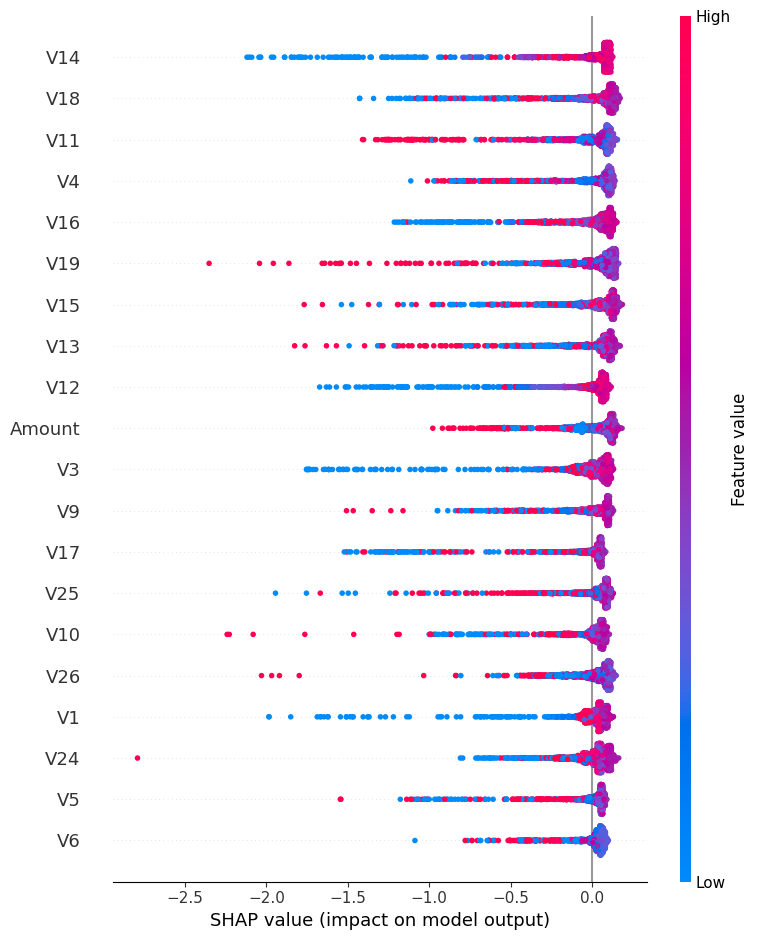

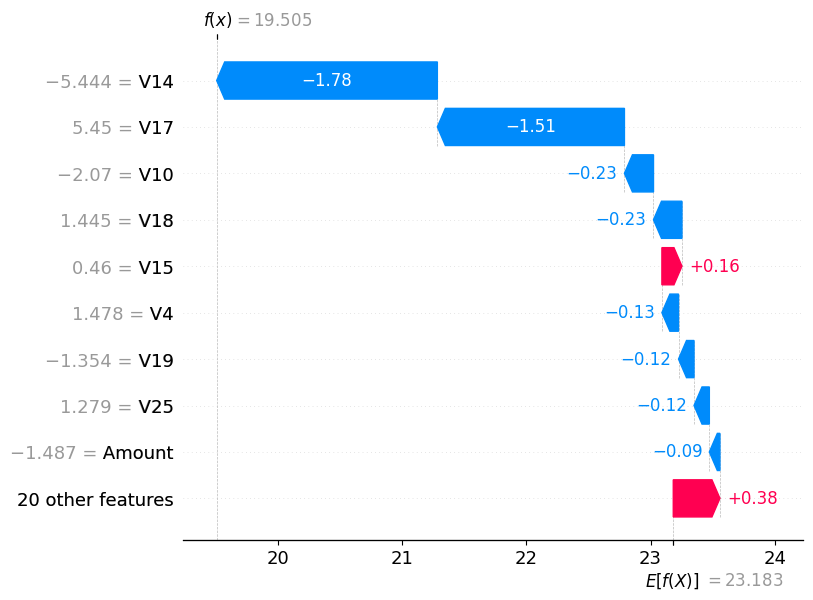

In [27]:
try:
    import shap
    explainer = shap.TreeExplainer(iso)      # Isolation Forest is a tree model, so TreeExplainer is exact for it
    sample = pd.concat([X_test[y_test == 0].sample(1500, random_state=42),
                        X_test[y_test == 1]])
    sv = explainer.shap_values(sample)
    shap.summary_plot(sv, sample)

    fraud_pos = np.where(y_test.loc[sample.index].values == 1)[0][0]
    shap.plots.waterfall(explainer(sample)[fraud_pos])
except Exception as e:
    print("SHAP (Isolation Forest) skipped:", repr(e))

V17    180.604446
V12     67.850700
V14     61.516853
V10     54.177589
V7      49.817932
V16     45.036343
V3      41.082218
V5      23.954262
dtype: float32


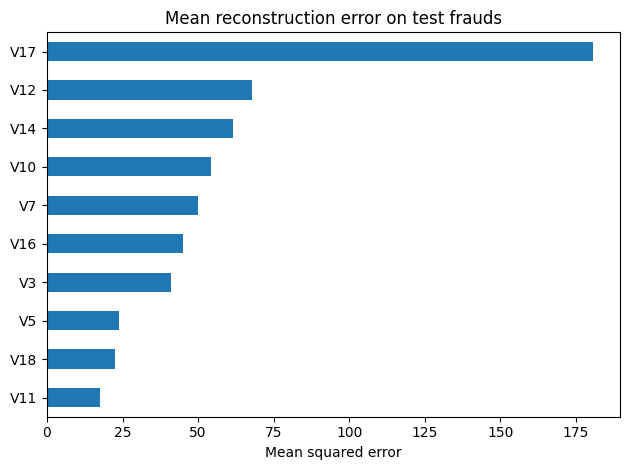

In [28]:
# Which features make the autoencoder's reconstruction error large for frauds?
fraud_rows = X_test[y_test == 1]
ae.eval()
with torch.no_grad():
    tt = torch.tensor(fraud_rows.values, dtype=torch.float32).to(device)
    err_all = ((tt - ae(tt)) ** 2).cpu().numpy()

mean_err = pd.Series(err_all.mean(axis=0), index=fraud_rows.columns).sort_values(ascending=False)
print(mean_err.head(8))

mean_err.head(10)[::-1].plot(kind="barh", title="Mean reconstruction error on test frauds")
plt.xlabel("Mean squared error"); plt.tight_layout(); plt.show()

  0%|          | 0/20 [00:00<?, ?it/s]

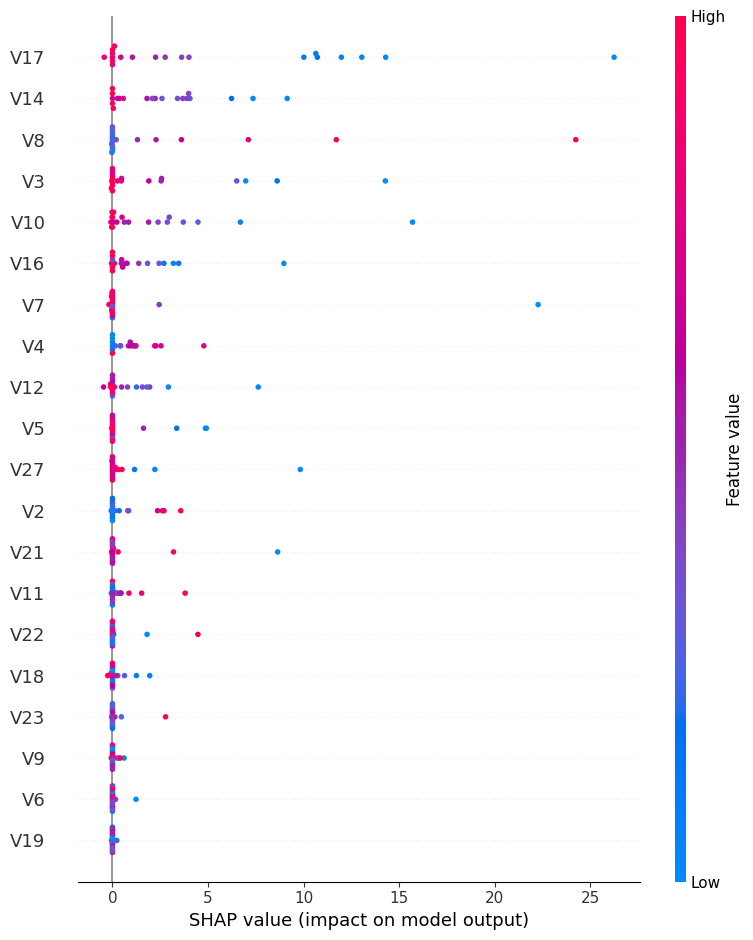

In [29]:
try:
    import shap

    def ae_score(arr):
        t = torch.tensor(arr, dtype=torch.float32).to(device)
        ae.eval()
        with torch.no_grad():
            return ((t - ae(t)) ** 2).mean(dim=1).cpu().numpy()

    background = shap.sample(X_train_normal.values, 100, random_state=42)
    frauds20 = X_test[y_test == 1].values[:20]
    kernel_explainer = shap.KernelExplainer(ae_score, background)       # model-agnostic, approximate
    sv_ae = kernel_explainer.shap_values(frauds20, nsamples=200)
    shap.summary_plot(sv_ae, frauds20, feature_names=list(X_test.columns))
except Exception as e:
    print("SHAP (autoencoder) skipped:", repr(e))

## 14. Gradio demo app (final cell)
Opens a web app with a temporary public link. Try *Load a fraud example* then *Check transaction*, and upload `sample_transactions.csv` (click the folder icon on the left to find it) in the batch tab; `answer_key.csv` holds the true labels.
`HIGH` = XGBoost flags it (main decision). `REVIEW` = only the autoencoder finds it unusual: a low-confidence signal (about 1 in 15 such rows were real frauds in testing), not an alert. Contributions explain what drove a score; they are **not proof of fraud**.

In [30]:
import importlib, subprocess, sys
try:
    importlib.import_module("gradio")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])

import gradio as gr, random, json

try:
    demo.close()                       # lets you re-run this cell without a port clash
except Exception:
    pass

gold_raw = pd.read_csv(os.path.join(WORK, "golden_scores.csv"))
fraud_examples  = gold_raw[gold_raw["y_true"] == 1].drop(columns=["xgb_prob", "ae_score", "xgb_flag", "ae_flag", "y_true"])
normal_examples = gold_raw[gold_raw["y_true"] == 0].drop(columns=["xgb_prob", "ae_score", "xgb_flag", "ae_flag", "y_true"])

def example(kind):
    pool = fraud_examples if kind == "fraud" else normal_examples
    return json.dumps(pool.sample(1).iloc[0].to_dict())

MESSAGES = {"HIGH": "HIGH RISK - flagged as likely fraud by XGBoost",
            "REVIEW": "REVIEW - XGBoost says normal, but the autoencoder finds it unusual",
            "LOW": "LOW RISK - looks genuine"}

def check_one(text):
    try:
        feats = json.loads(text)
        feats = feats.get("features", feats)
        o = core.predict_one(feats)
    except Exception as e:
        return f"Could not score this input: {e}", {}, pd.DataFrame()
    lines = [MESSAGES[o["risk_level"]],
             f"XGBoost fraud probability: {o['xgb_probability']:.4f}  (flag threshold {o['xgb_threshold']:.4f})"]
    if "ae_score" in o:
        lines.append(f"Autoencoder score: {o['ae_score']}  (flag threshold {o['ae_threshold']})")
    rows = [{"model": "XGBoost", "feature": d["feature"], "value": d["contribution"],
             "meaning": "pushes toward fraud (+) or genuine (-)"} for d in o["xgb_top_drivers"]]
    rows += [{"model": "Autoencoder", "feature": d["feature"], "value": d["error"],
              "meaning": "reconstruction error"} for d in o.get("ae_top_errors", [])]
    p = o["xgb_probability"]
    return "\n".join(lines), {"Fraud": p, "Genuine": 1 - p}, pd.DataFrame(rows)

def check_batch(file):
    if file is None:
        return None, "Please upload a CSV file."
    try:
        fpath = file if isinstance(file, str) else file.name
        data = pd.read_csv(fpath).drop(columns=["Class"], errors="ignore")
        r = core.predict_df(data)
    except Exception as e:
        return None, f"Could not score this file: {e}"
    table = r.copy()
    table.insert(0, "row", range(len(table)))
    table["xgb_probability"] = table["xgb_probability"].round(4)
    if "ae_score" in table:
        table["ae_score"] = table["ae_score"].round(3)
    counts = r["risk_level"].value_counts().to_dict()
    return table, f"{len(r)} transactions scored. HIGH: {counts.get('HIGH', 0)} | REVIEW: {counts.get('REVIEW', 0)} | LOW: {counts.get('LOW', 0)}"

with gr.Blocks(title="Fraud Detection") as demo:
    gr.Markdown("## Fraud Detection demo\nXGBoost (supervised) makes the main decision; the autoencoder (unsupervised) gives a second opinion. "
                "Examples are held-out test transactions. Contributions explain what drove a score; they are **not proof of fraud**.")
    with gr.Tab("Single transaction"):
        box = gr.Textbox(label="Transaction JSON (V1..V28 and Amount; Time is optional)", lines=8)
        with gr.Row():
            b_norm = gr.Button("Load a genuine example")
            b_fraud = gr.Button("Load a fraud example")
            b_go = gr.Button("Check transaction", variant="primary")
        verdict = gr.Textbox(label="Result", lines=4)
        probs = gr.Label(label="XGBoost probability")
        drivers = gr.Dataframe(label="Top features behind the scores")
        b_norm.click(lambda: example("normal"), outputs=box)
        b_fraud.click(lambda: example("fraud"), outputs=box)
        b_go.click(check_one, inputs=box, outputs=[verdict, probs, drivers])
    with gr.Tab("Batch (CSV upload)"):
        file_in = gr.File(label="Upload CSV (columns: V1..V28, Amount; Time and Class are ignored)", file_types=[".csv"])
        b_run = gr.Button("Check all transactions", variant="primary")
        summary = gr.Textbox(label="Summary")
        table = gr.Dataframe(label="Results")
        b_run.click(check_batch, inputs=file_in, outputs=[table, summary])

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4ad3ff7f61226fad14.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
